## Submission & Learning Opportunity: Hill of Towie Wind Turbine Power Prediction

[Kaggle: hill-of-towie-wind-turbine-power-prediction](https://www.kaggle.com/competitions/hill-of-towie-wind-turbine-power-prediction/overview)

| Date        | Score       | Comment                                                              |
| ----------- | ----------- |  ------------------------------------------------------------------  |
| 20250724    | 56.67       | First attempt, HistGradientBoostingRegressor, No Feature Engineering |
| 20250724    | 56.53       | Wind speed estimate using HistGradientBoostingRegressor              |
| 20250724    | 56.29       | Added elapsed seconds,cyclic hour encoding and lagging features      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |
|             |             |                                                                      |

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import kagglehub
from kagglehub.config import DEFAULT_CACHE_FOLDER
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

/Users/joarsolvang/Documents/Github/floris-timeseries/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CACHE_DIR = Path(DEFAULT_CACHE_FOLDER) / "competitions" / "hill-of-towie-wind-turbine-power-prediction"


def load_training_dataset(*, force_download: bool = False) -> pd.DataFrame:
    file_path = kagglehub.competition_download(
        handle="hill-of-towie-wind-turbine-power-prediction",
        path="training_dataset.parquet",
        force_download=force_download,
    )
    return pd.read_parquet(Path(file_path))

In [3]:
complete_data = load_training_dataset()
complete_data= complete_data.set_index('TimeStamp_StartFormat')
complete_data.dropna(inplace=True)

pc_data = complete_data[["wtc_ActPower_mean;1", "wtc_AcWindSp_mean;1"]]
pc_data = pc_data[pc_data["wtc_ActPower_mean;1"] > 20]
bins = pd.interval_range(start=0, end=25, freq=0.5)
pc_data["wind_speed_bin"] = pd.cut(
    pc_data["wtc_AcWindSp_mean;1"],
    bins=bins
)
pc_data.dropna(inplace=True)
power_curve = pc_data.groupby(
    "wind_speed_bin", observed=True
).agg(
    power_mean = ("wtc_ActPower_mean;1", "mean"),
    power_std = ("wtc_ActPower_mean;1", "std"),
    power_count = ("wtc_ActPower_mean;1", "count")
).reset_index()

In [4]:
power_curve["wind_speed_bin_mid"] = power_curve["wind_speed_bin"].apply(lambda x: x.mid)

In [5]:
from scipy.interpolate import CubicSpline

wind_speed_power_interpolator = CubicSpline(
    power_curve["wind_speed_bin_mid"],
    power_curve["power_mean"]
)



In [6]:

complete_data = complete_data.drop('target', axis=1)

In [7]:
# training_data = complete_data.drop(labels=T1_tags, axis=1)

training_columns = complete_data.columns
ws_tags = [tag for tag in training_columns if "AcWindSp_mean" in tag]
power_tags = [tag for tag in training_columns if "ActPower_mean" in tag]
yaw_tags = [tag for tag in training_columns if "ScYawPos_mean" in tag]

# Extract the hour
complete_data["hour"] = complete_data.index.hour

# Encode hour as cyclic features
complete_data["hour_sin"] = np.sin(2 * np.pi * complete_data["hour"] / 24)
complete_data["hour_cos"] = np.cos(2 * np.pi * complete_data["hour"] / 24)


complete_data["time_delta_seconds"] = (complete_data.index - complete_data.index[0]).map(lambda x: x.total_seconds())
complete_data["mean_yaw_direction"] = complete_data[yaw_tags].mean(axis=1)

for power_tag in power_tags:
    for lag in [1,2,3]:
        complete_data[power_tag + f"_lagging_{lag}"] = complete_data[power_tag].shift(-lag)

for power_tag in power_tags:
    for window in [3,6,9]:
        complete_data[power_tag + f"_window_{window}"] = complete_data[power_tag].rolling(window=window, center=False).mean()


for ws_tag in ws_tags:
    for lag in [1,2,3]:
        complete_data[ws_tag + f"_lagging_{lag}"] = complete_data[ws_tag].shift(-lag)

for ws_tag in ws_tags:
    for window in [3,6,9]:
        complete_data[ws_tag + f"_window_{window}"] = complete_data[ws_tag].rolling(window=window, center=False).mean()



In [8]:
for ws_tag in ws_tags[1:]:
    print(ws_tag)
    complete_data[f"expected_power_{ws_tag}"] = wind_speed_power_interpolator(complete_data[ws_tag])

wtc_AcWindSp_mean;2
wtc_AcWindSp_mean;3
wtc_AcWindSp_mean;4
wtc_AcWindSp_mean;5
wtc_AcWindSp_mean;7


Let's add some basic feature engineering:
- Time elapsed
- Rolling averages 
- Day of week

In [9]:
training_set = complete_data.loc[complete_data.index < pd.Timestamp(day=1, month=1, year=2019, tz="UTC")].copy()
testing_set = complete_data.loc[complete_data.index >= pd.Timestamp(day=1, month=1, year=2019, tz="UTC")].copy()

Let's start off with some feature engineering. We'll take it back to basics:

$$
P = \frac{1}{2} \rho A v^3 C_p
$$


Possible feature engineering:
- Turbine Wind Speed
- Density 
- Yaw misalignment, yaw error off a concencus wind direction
- Cp 

In [10]:
columns = complete_data.columns
era5_tags = [tag for tag in columns if "ERA" in tag]
T1_tags = [tag for tag in columns if ";1" in tag]

training_target_set = training_set[T1_tags]
training_inputs = training_set.drop(labels=T1_tags, axis=1)

testing_target_set = testing_set[T1_tags]
testing_inputs = testing_set.drop(labels=T1_tags, axis=1)
target_tag = "wtc_ActPower_mean;1"

/Users/joarsolvang/Documents/Github/floris-timeseries/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


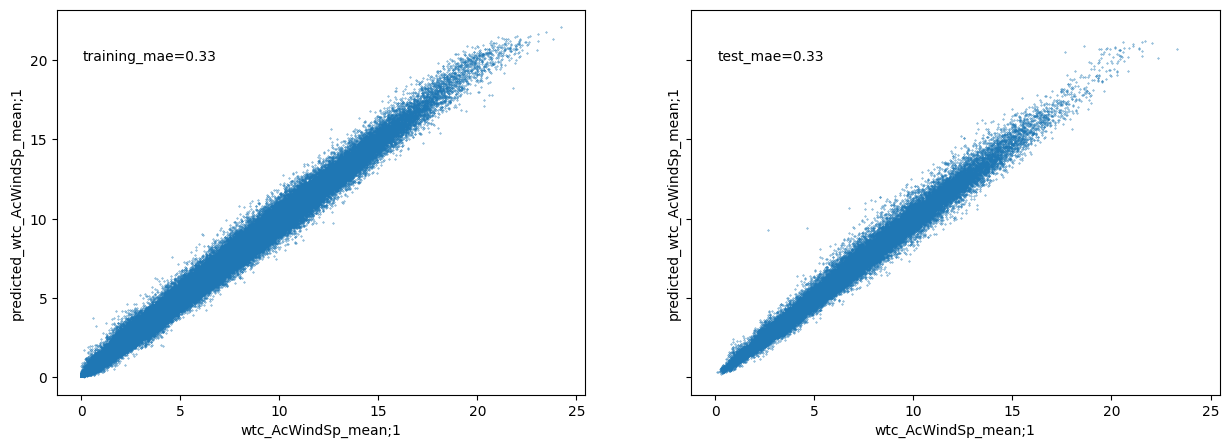

In [11]:
wind_speed_target_tag = 'wtc_AcWindSp_mean;1'

model = HistGradientBoostingRegressor()
model.fit(training_inputs, training_target_set[[wind_speed_target_tag]])
test_predicted_ws = model.predict(testing_inputs)
training_predicted_ws = model.predict(training_inputs)

test_predicted_ws_df = pd.DataFrame(
    test_predicted_ws,
    columns=["predicted_power"],
    index=testing_inputs.index
    )


training_prediction_ws_df = pd.DataFrame(
    training_predicted_ws,
    columns=["predicted_power"],
    index=training_inputs.index
    )

test_mae = mean_absolute_error(testing_target_set[[wind_speed_target_tag]], test_predicted_ws_df)
training_mae = mean_absolute_error(training_target_set[[wind_speed_target_tag]], training_prediction_ws_df)

fig, ax = plt.subplots(ncols=2, figsize=(15, 5), sharex=True, sharey=True)
ax[0].scatter(training_target_set[[wind_speed_target_tag]], training_prediction_ws_df, s=.1)
ax[0].annotate(text=f"{training_mae=:.2f}", xy=(.1,20))
ax[0].set_xlabel(wind_speed_target_tag)
ax[0].set_ylabel("predicted_" + wind_speed_target_tag)

ax[1].scatter(testing_target_set[[wind_speed_target_tag]], test_predicted_ws_df, s=.1)
ax[1].annotate(text=f"{test_mae=:.2f}", xy=(.1,20))
ax[1].set_xlabel(wind_speed_target_tag)
ax[1].set_ylabel("predicted_" + wind_speed_target_tag)
plt.show()

In [12]:
testing_inputs

,wtc_AcWindSp_mean;2,wtc_AcWindSp_mean;3,wtc_AcWindSp_mean;4,wtc_AcWindSp_mean;5,wtc_AcWindSp_mean;7,wtc_AcWindSp_min;2,wtc_AcWindSp_min;3,wtc_AcWindSp_min;4,wtc_AcWindSp_min;5,wtc_AcWindSp_min;7,...,wtc_AcWindSp_mean;5_window_6,wtc_AcWindSp_mean;5_window_9,wtc_AcWindSp_mean;7_window_3,wtc_AcWindSp_mean;7_window_6,wtc_AcWindSp_mean;7_window_9,expected_power_wtc_AcWindSp_mean;2,expected_power_wtc_AcWindSp_mean;3,expected_power_wtc_AcWindSp_mean;4,expected_power_wtc_AcWindSp_mean;5,expected_power_wtc_AcWindSp_mean;7
TimeStamp_StartFormat,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:00+00:00,13.164350,11.247780,11.088460,10.633830,13.023700,7.57,5.28,5.49,4.65,7.78,...,11.967537,12.321890,13.314367,12.805718,13.681103,2187.691906,1793.933674,1748.132870,1611.276830,2170.856506
2019-01-01 00:10:00+00:00,12.934900,10.462690,9.208033,10.016530,10.791330,7.78,5.49,4.49,4.65,6.22,...,11.037529,11.910134,12.591533,12.348522,13.230174,2158.931184,1558.765785,1162.101033,1418.436275,1659.223905
2019-01-01 00:20:00+00:00,9.532747,12.135450,11.797360,10.211640,12.683950,4.98,6.84,4.81,5.59,7.15,...,10.380664,11.654579,12.166327,12.453739,12.854862,1264.860330,2018.404809,1938.534078,1480.455635,2121.220825
2019-01-01 00:30:00+00:00,11.114430,12.331270,12.817890,11.345380,13.637120,6.42,6.74,8.30,6.84,7.88,...,10.906087,11.486531,12.370800,12.842583,12.660746,1755.715300,2059.142760,2141.976947,1821.039024,2224.598057
2019-01-01 00:40:00+00:00,11.960910,12.877810,13.767360,11.489690,13.011570,5.18,7.57,9.44,6.22,7.67,...,10.993387,11.030209,13.110880,12.851207,12.602641,1978.349036,2150.817737,2232.341555,1859.843628,2169.281736
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-12-31 23:10:00+00:00,6.674914,8.790455,9.309954,6.749103,9.335896,3.26,4.40,5.07,3.59,5.59,...,6.900208,6.999042,8.522439,8.339203,8.117804,431.820572,1027.462809,1194.558015,448.640462,1202.778914
2019-12-31 23:20:00+00:00,7.503870,8.951791,9.976680,8.194743,8.700228,3.59,4.98,6.94,4.57,4.65,...,7.250260,6.993488,8.877041,8.489922,8.251161,635.805109,1079.591591,1405.707775,838.815436,998.413298
2019-12-31 23:30:00+00:00,7.242282,7.387715,8.898215,7.778623,7.802809,4.98,4.49,5.49,5.18,5.28,...,7.472054,7.107894,8.612977,8.382486,8.290601,566.409305,604.339636,1062.270709,713.719351,720.779039


In [13]:
training_predicted_ws = model.predict(training_inputs)
testing_predicted_ws = model.predict(testing_inputs)
training_inputs["predicted_ws"] = training_predicted_ws
testing_inputs["predicted_ws"] = testing_predicted_ws

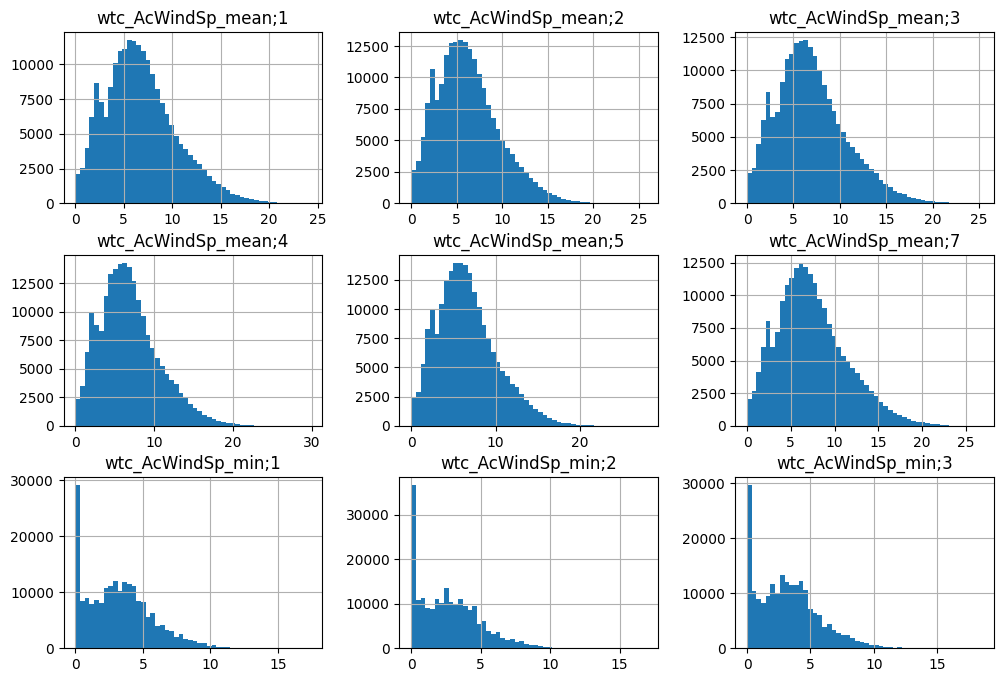

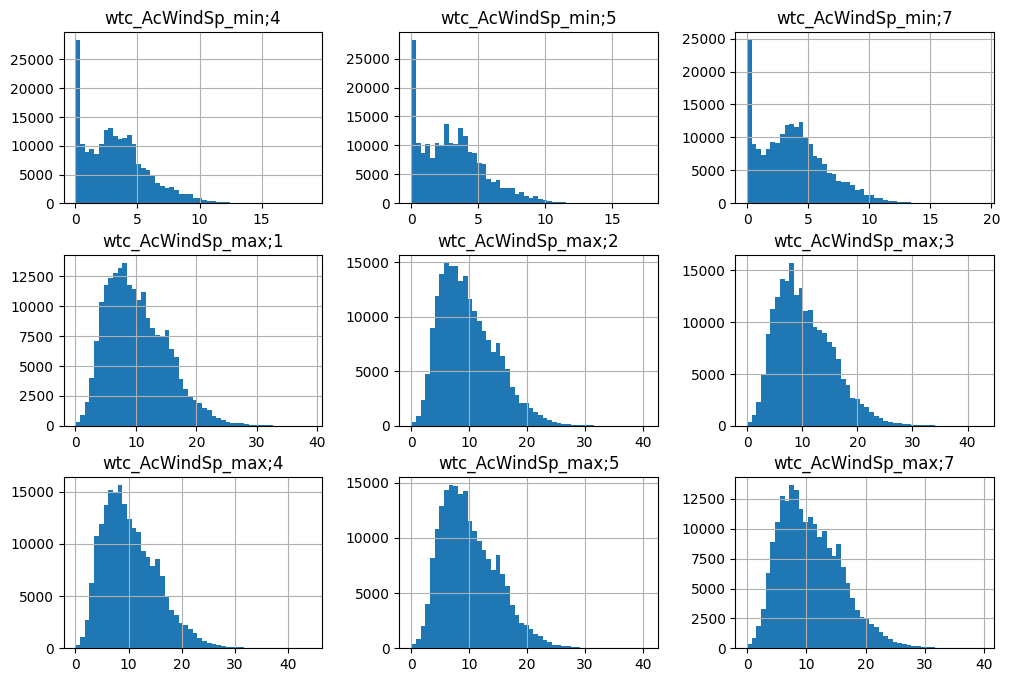

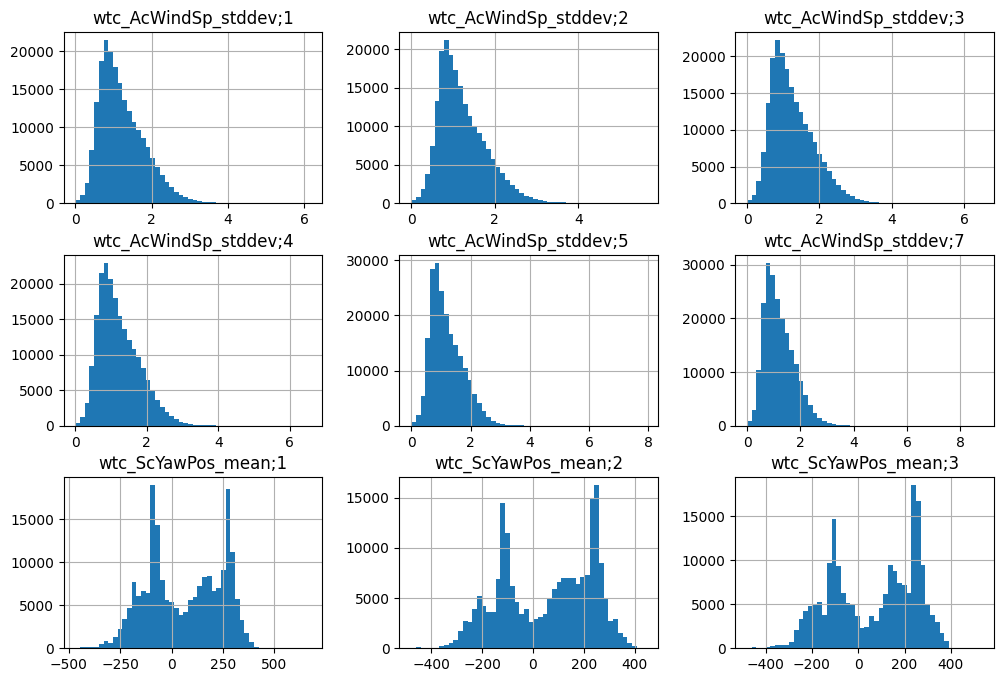

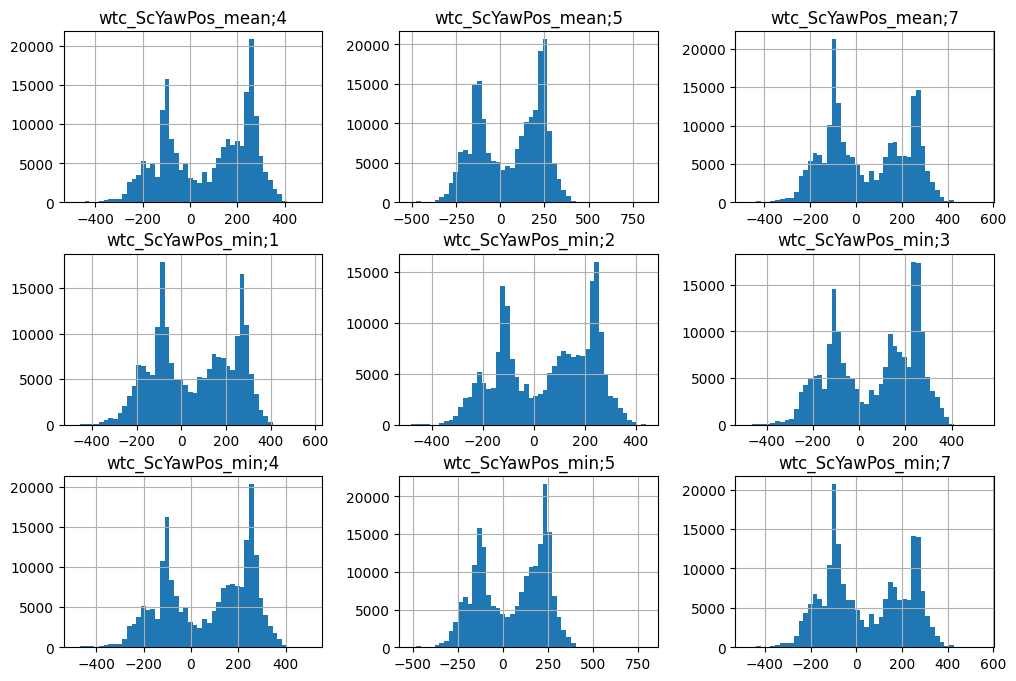

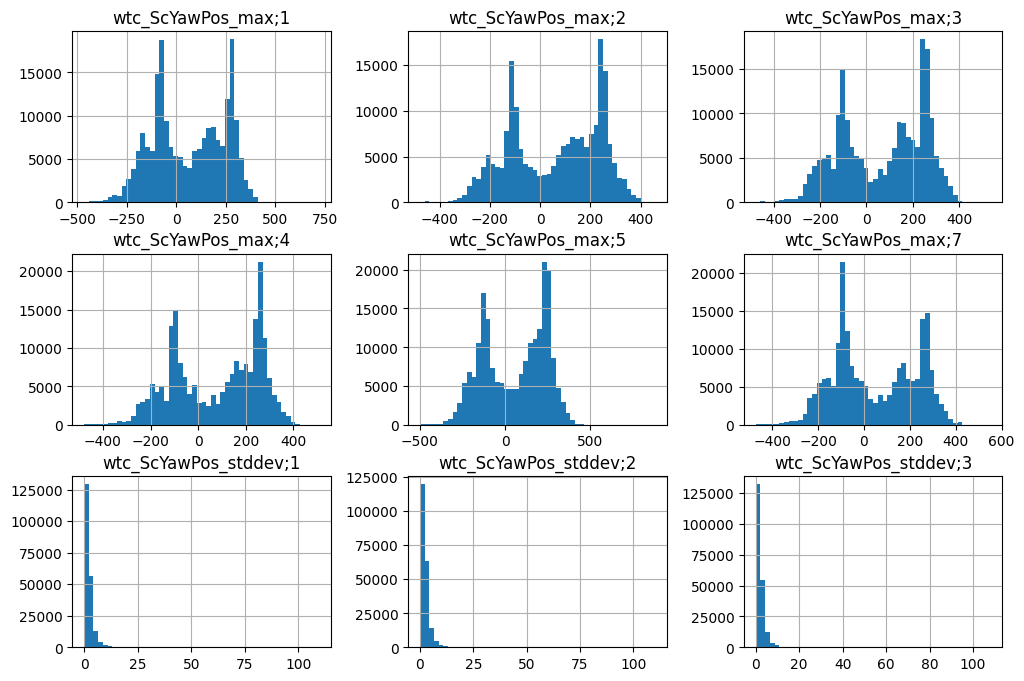

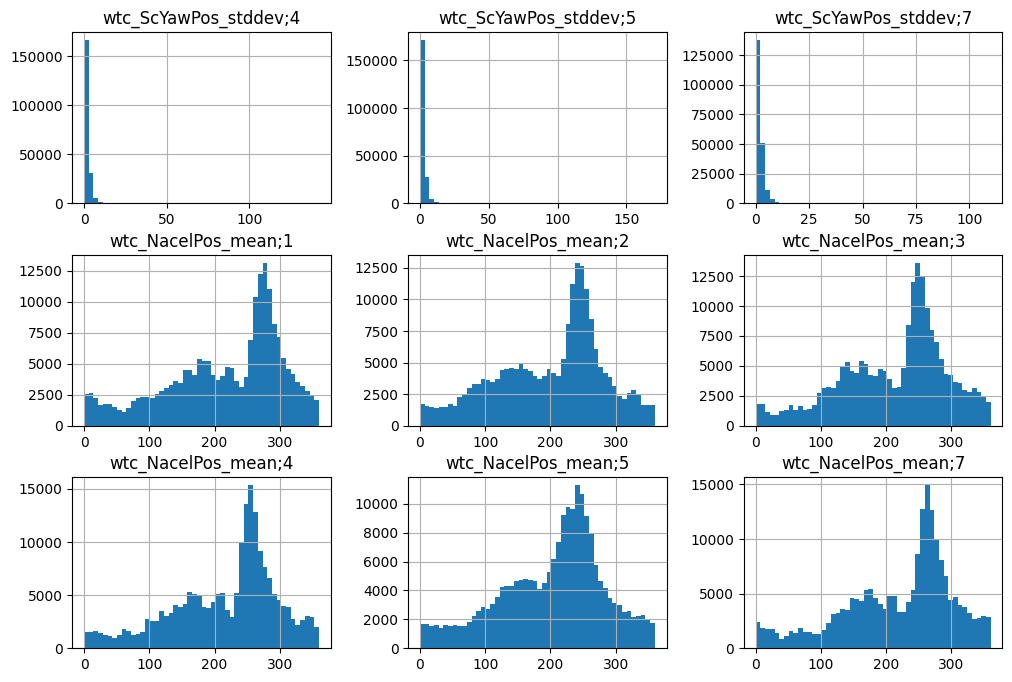

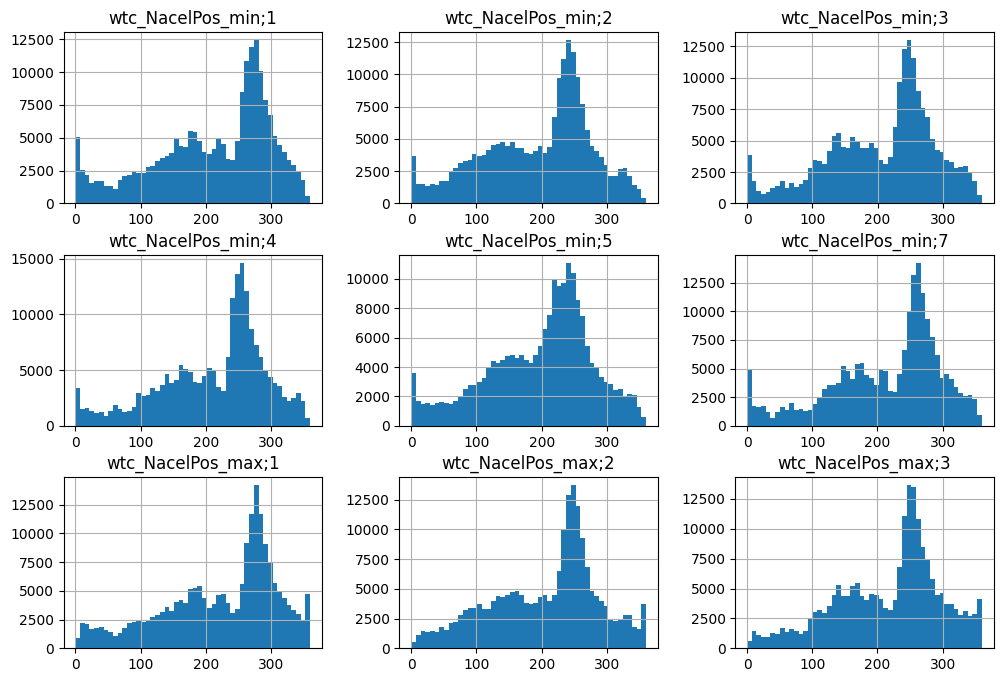

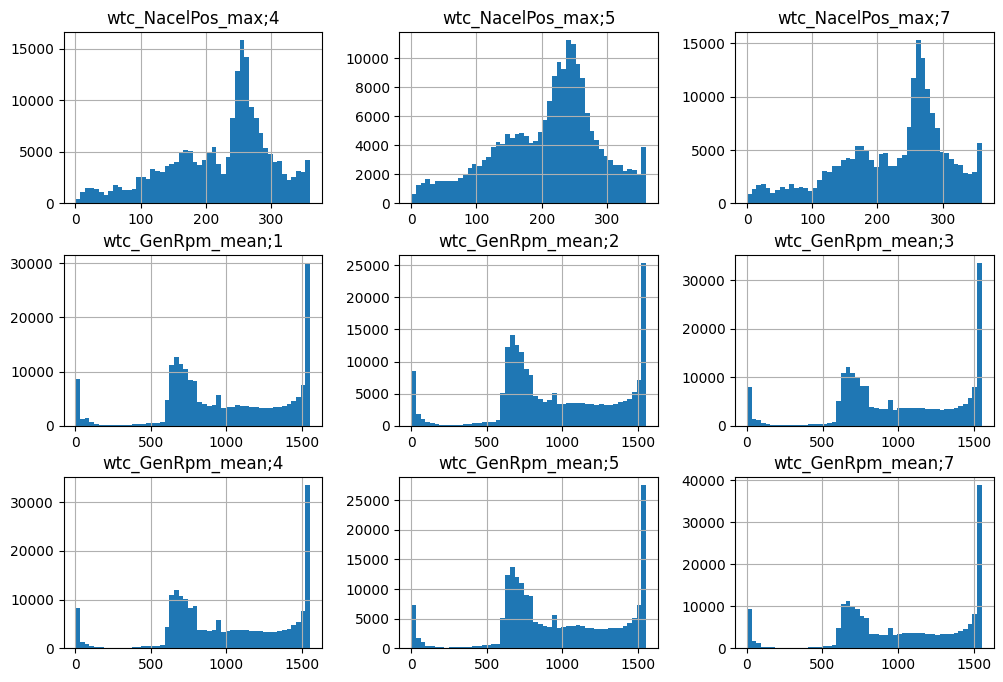

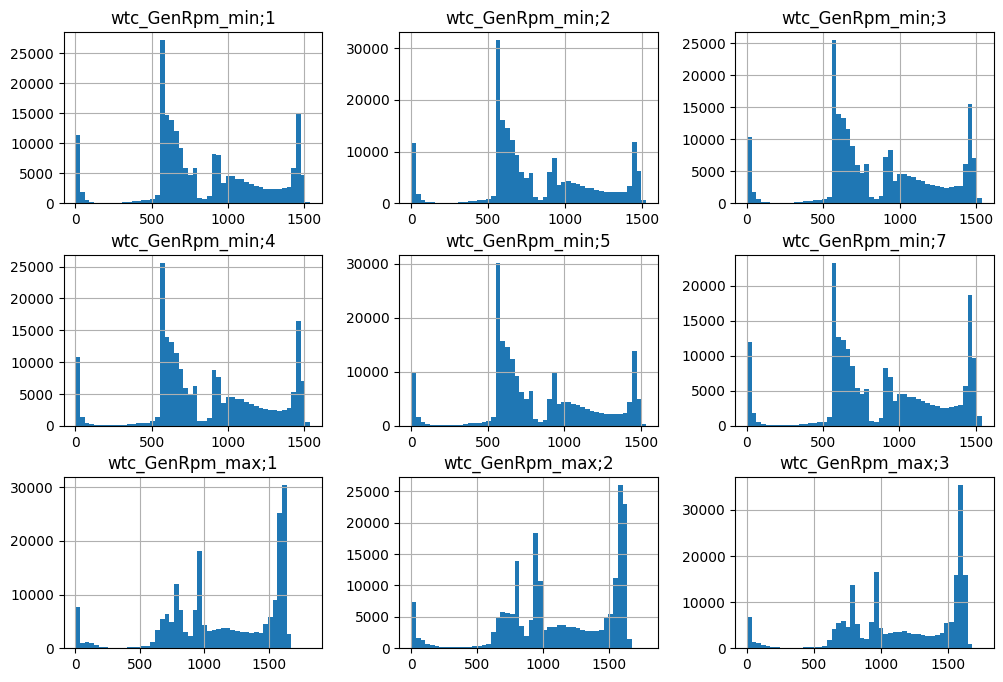

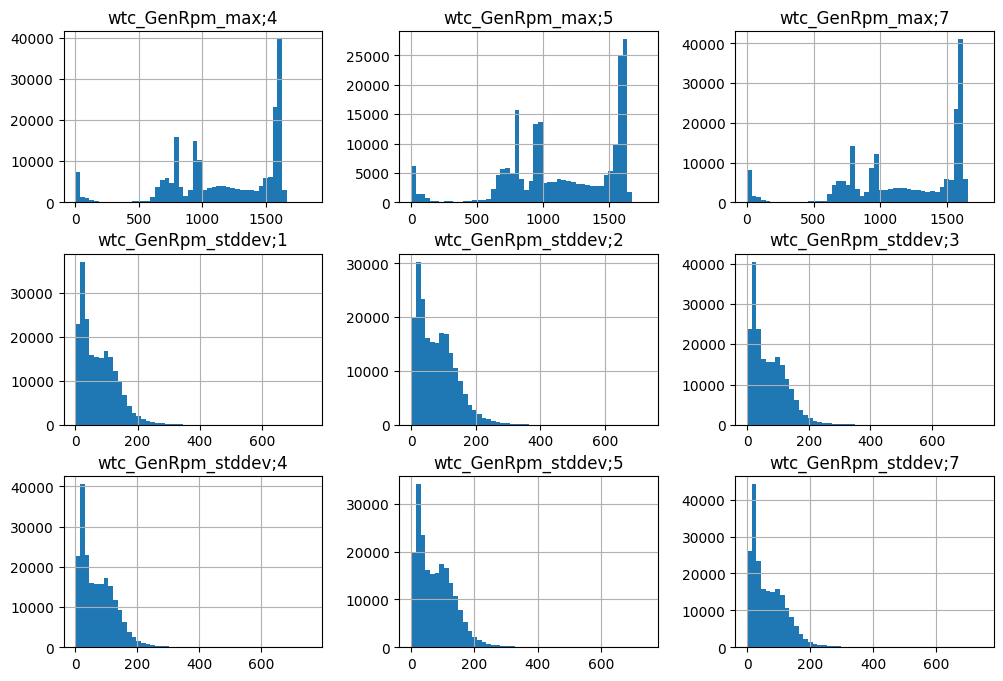

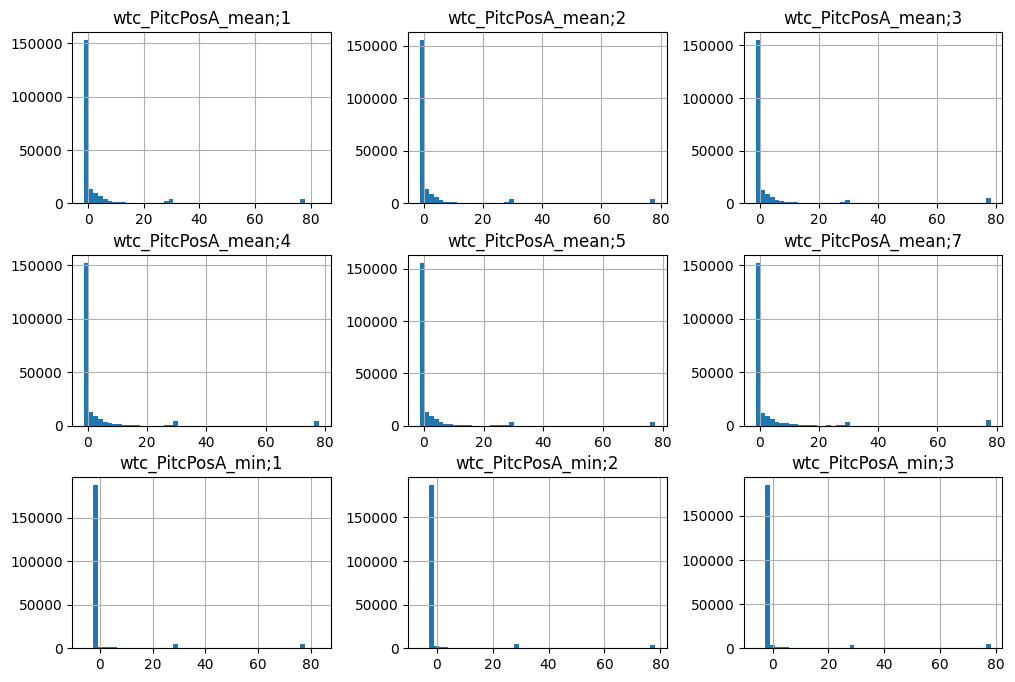

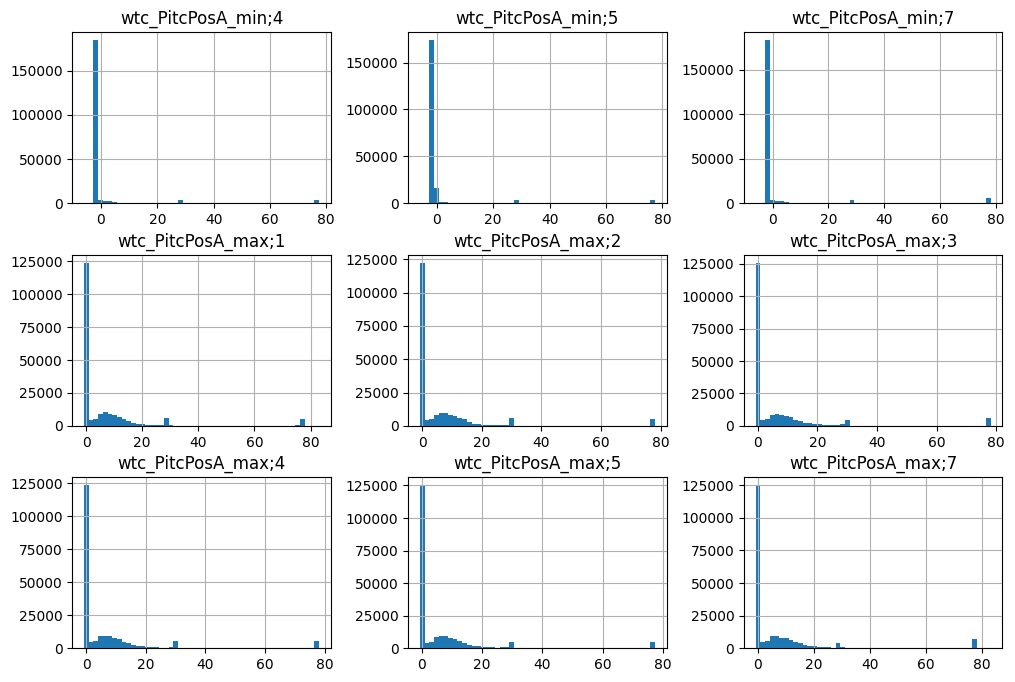

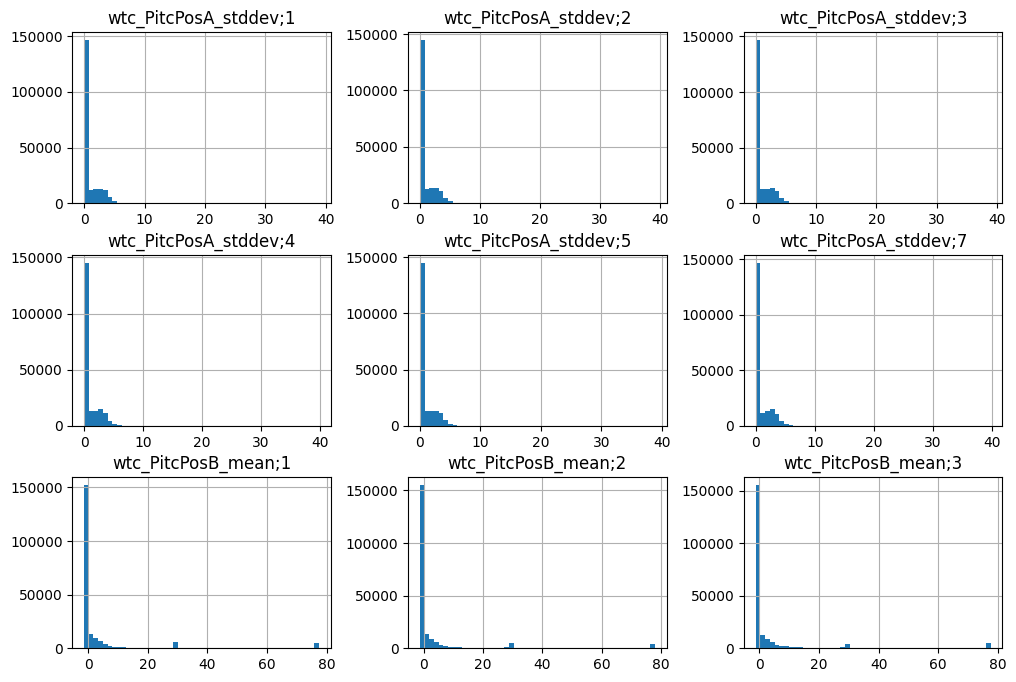

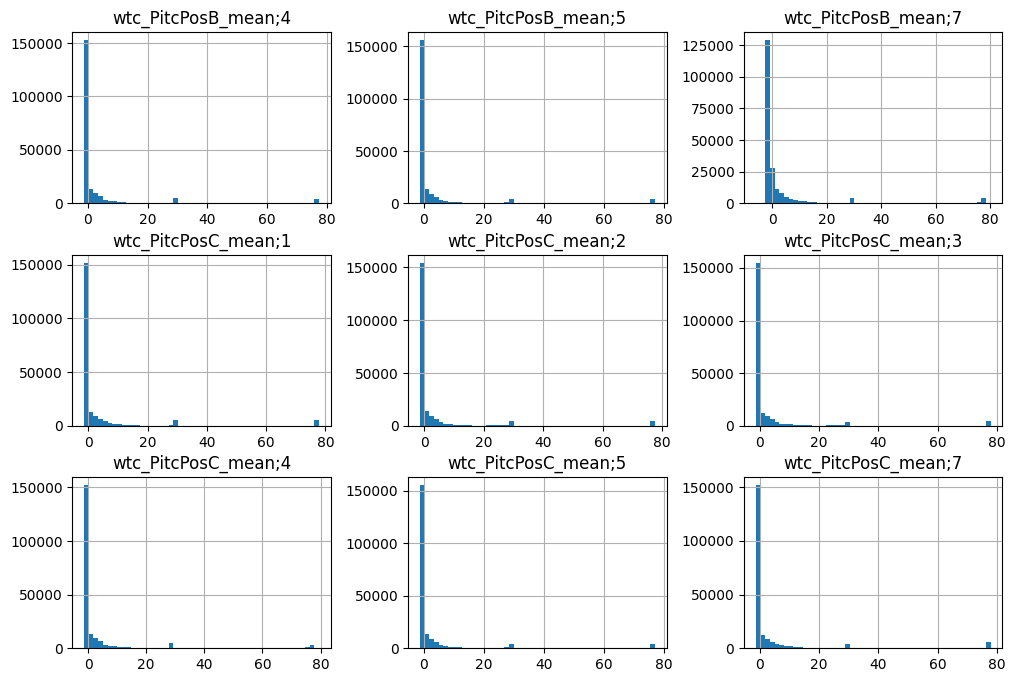

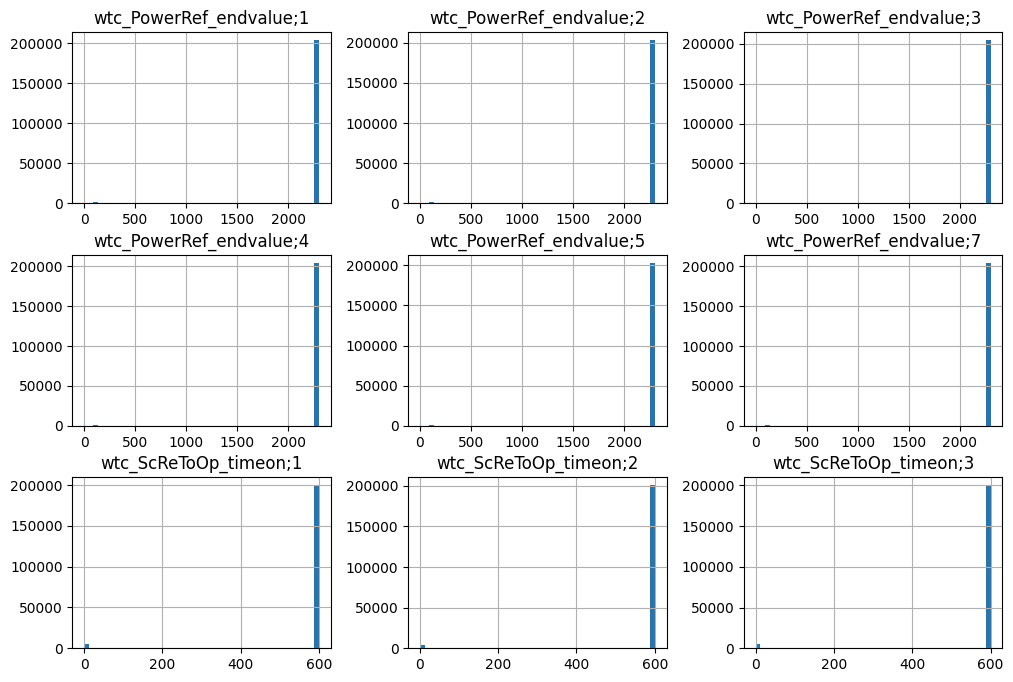

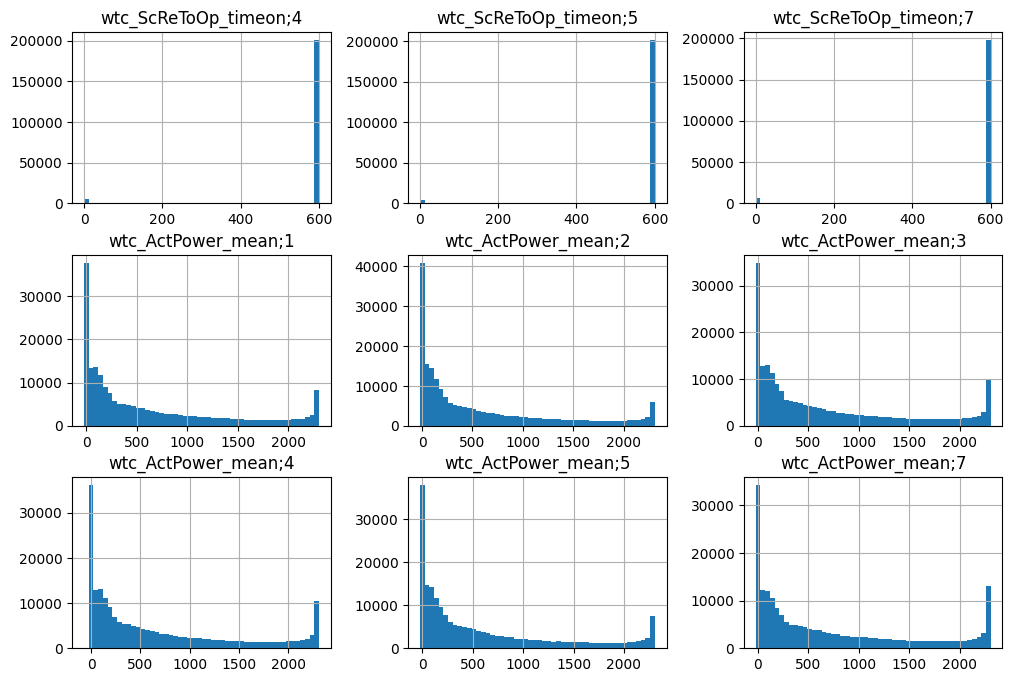

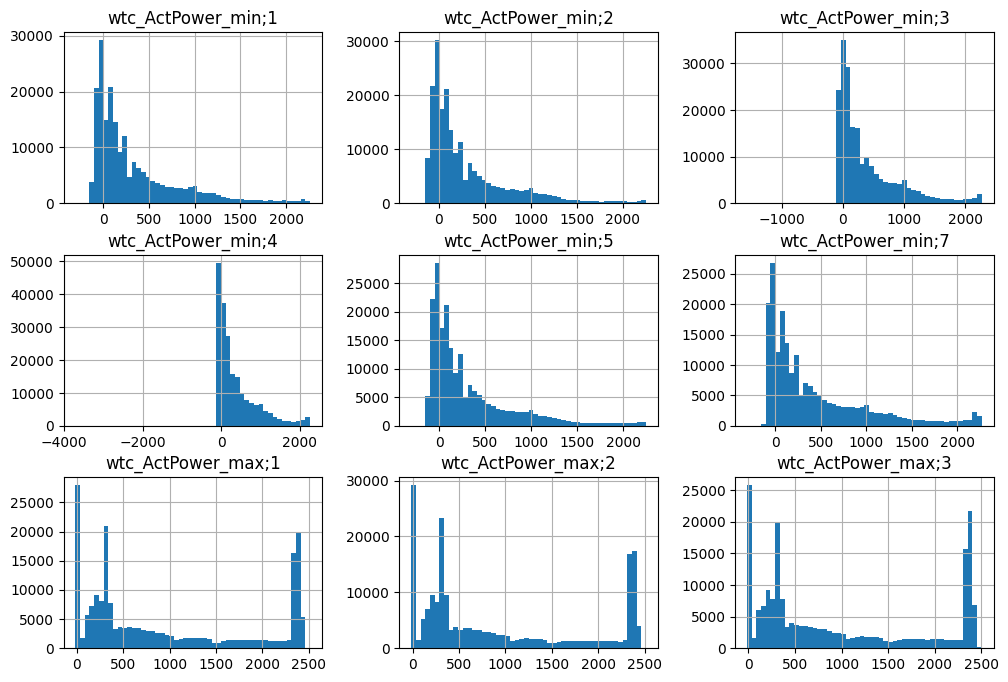

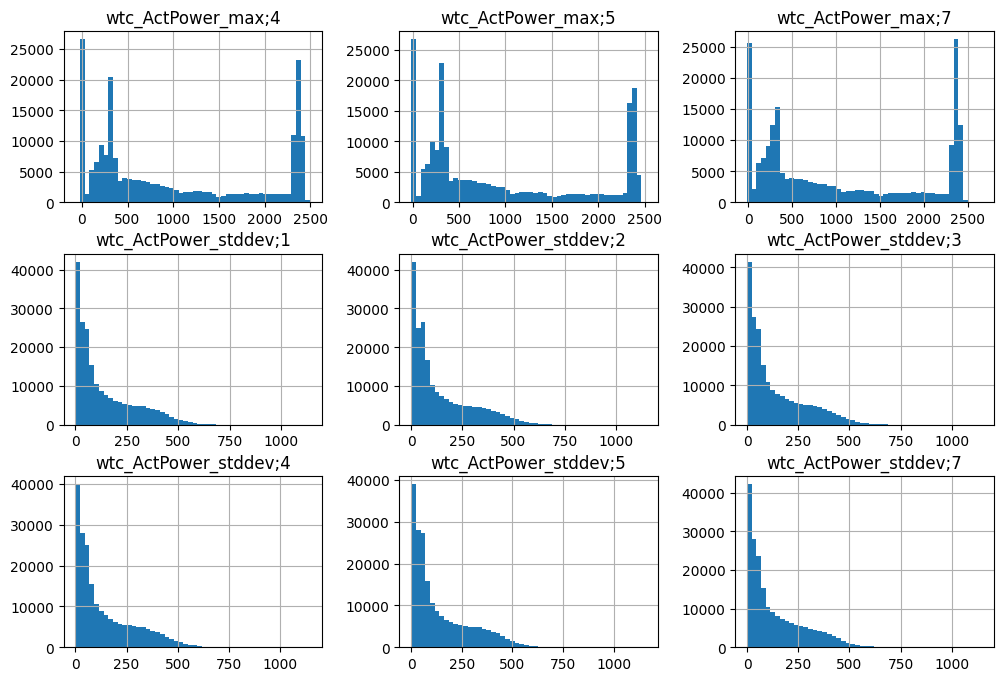

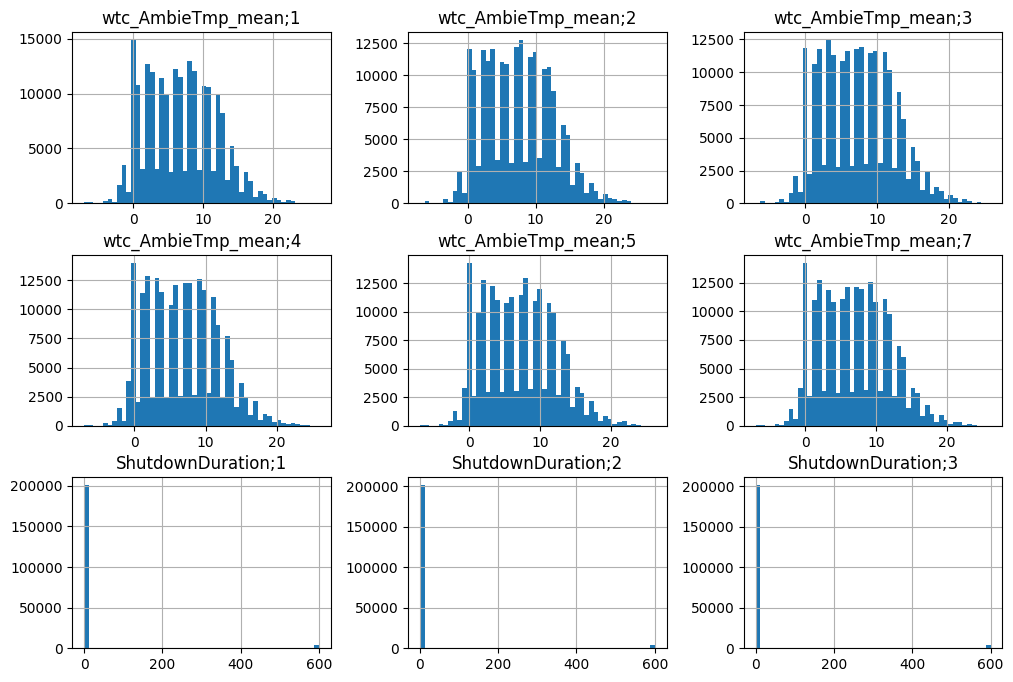

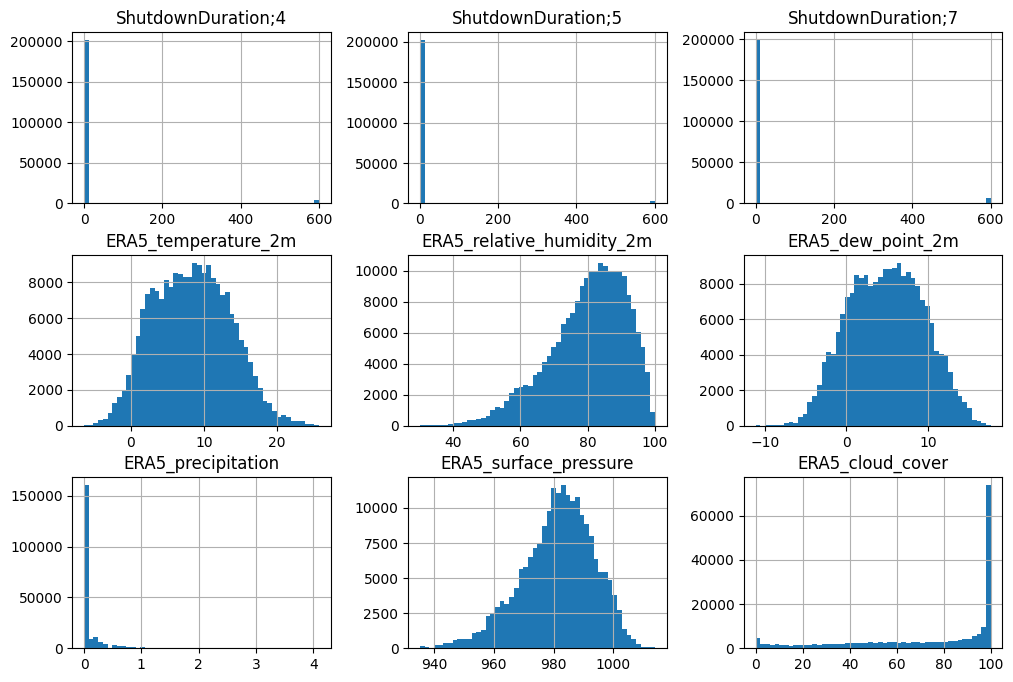

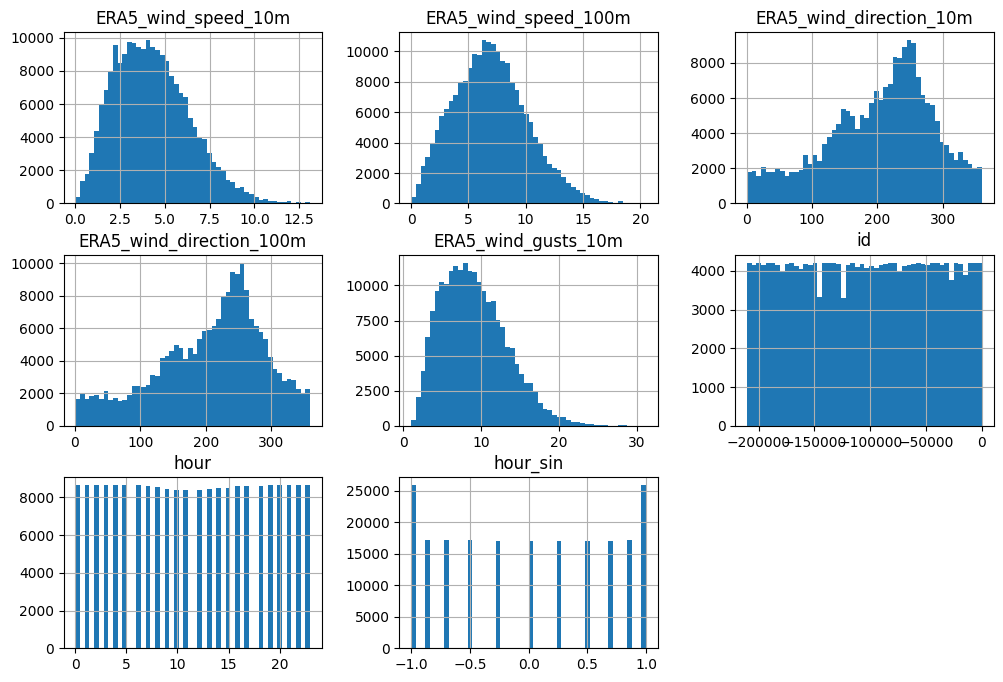

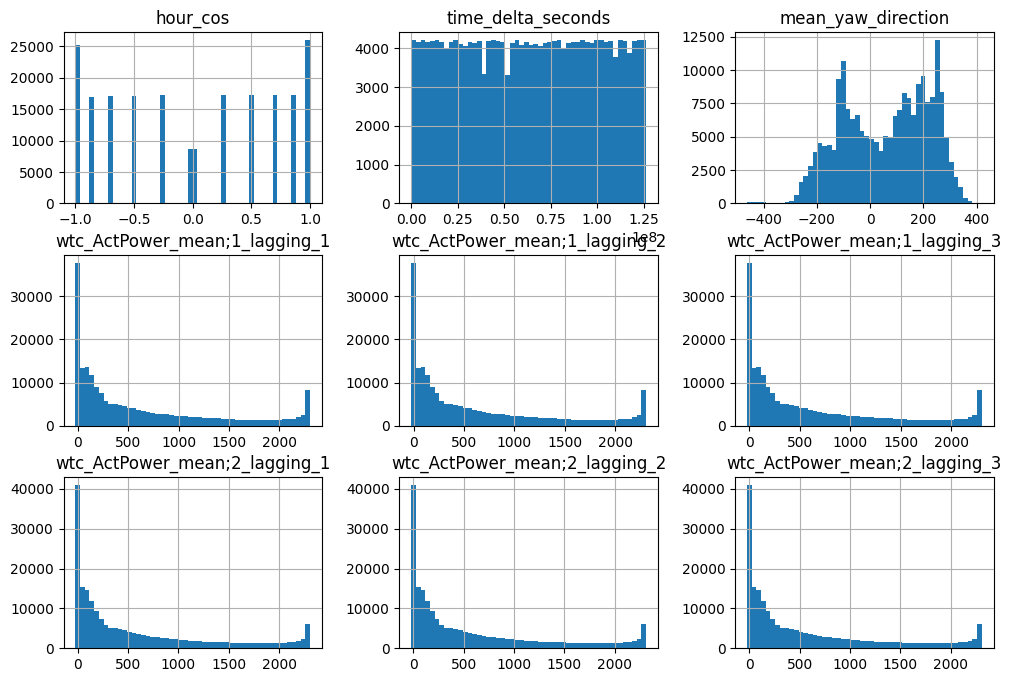

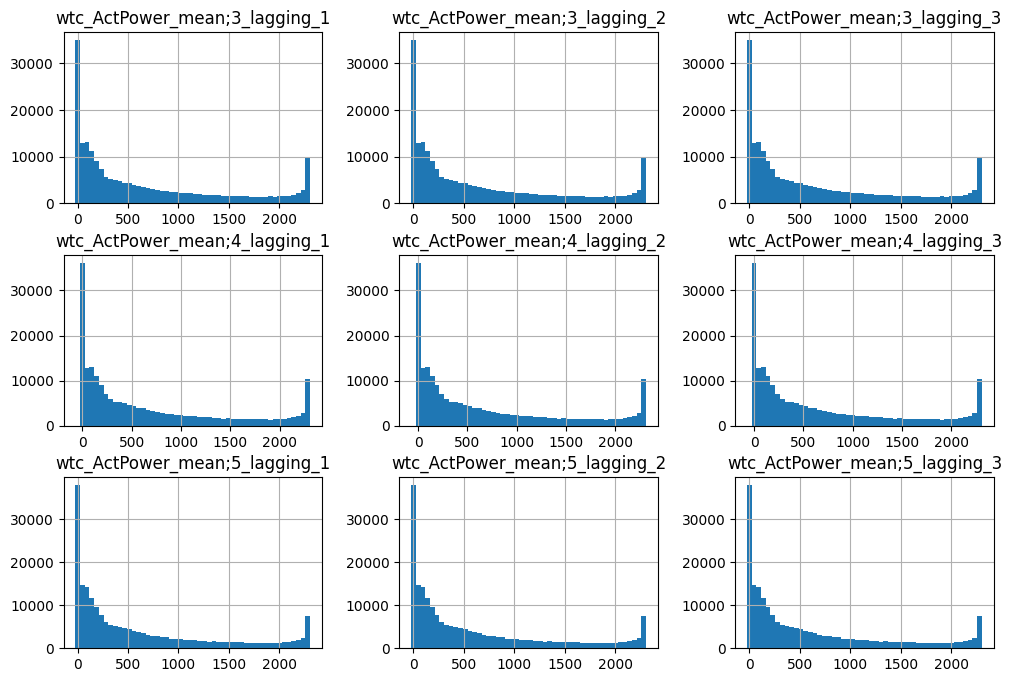

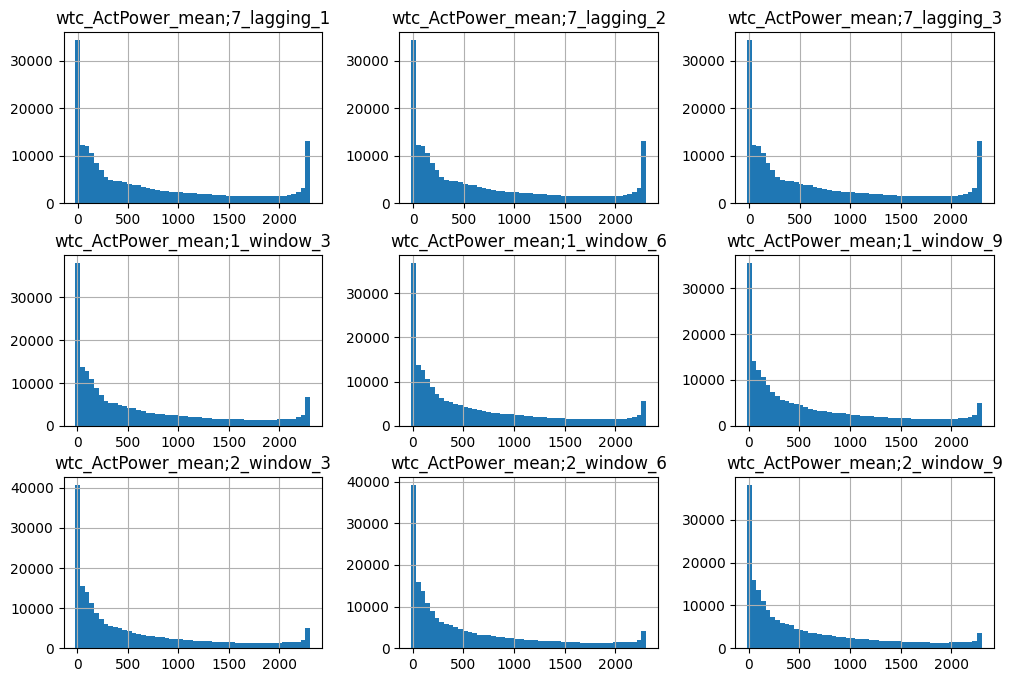

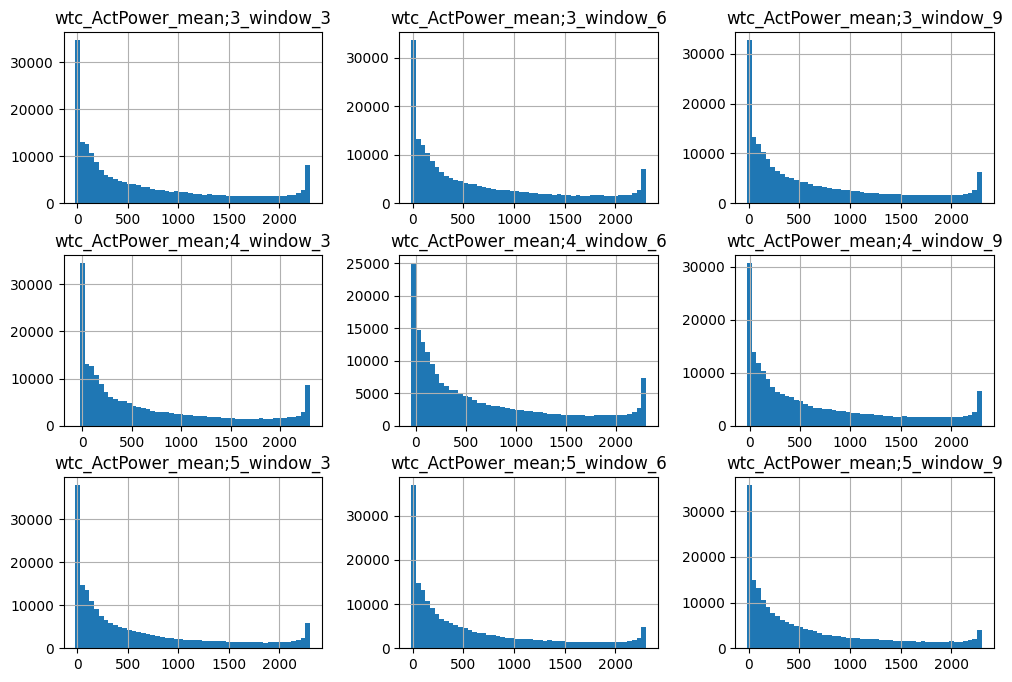

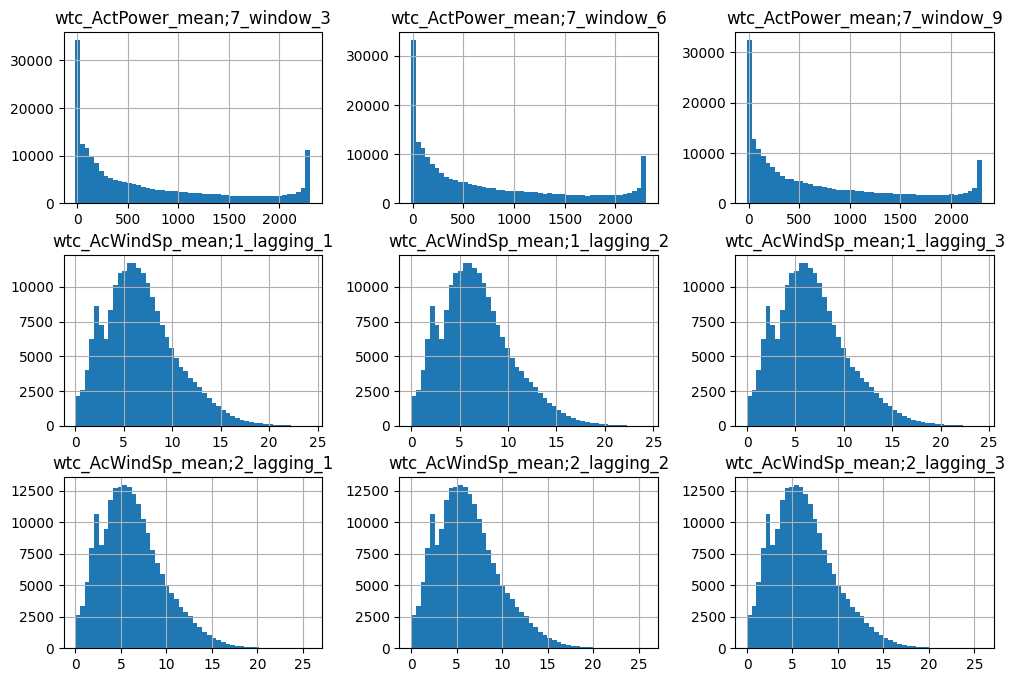

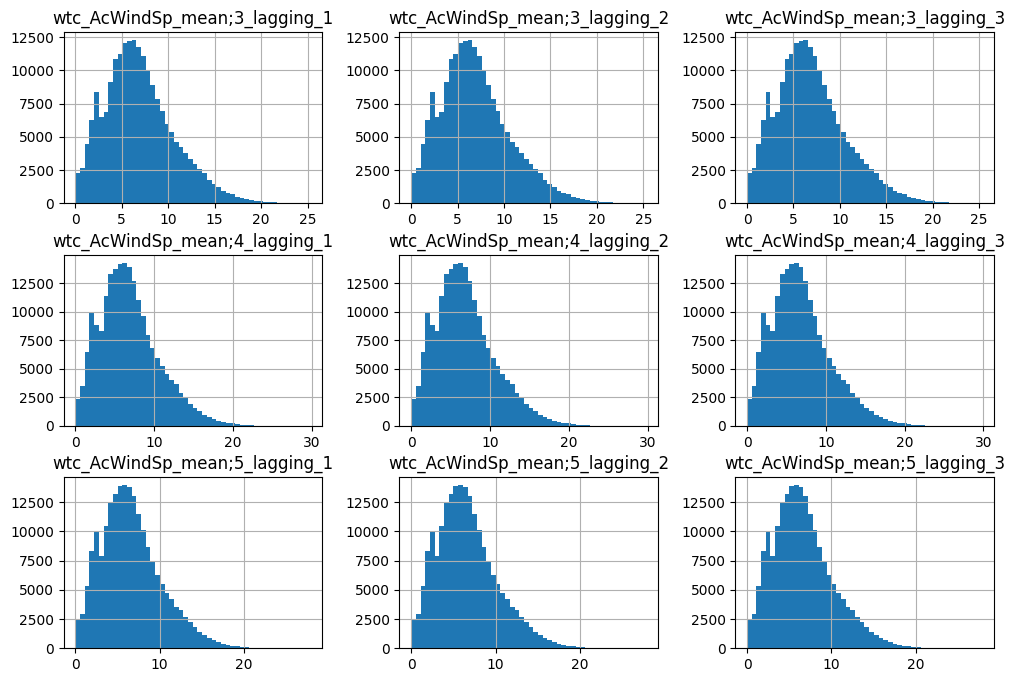

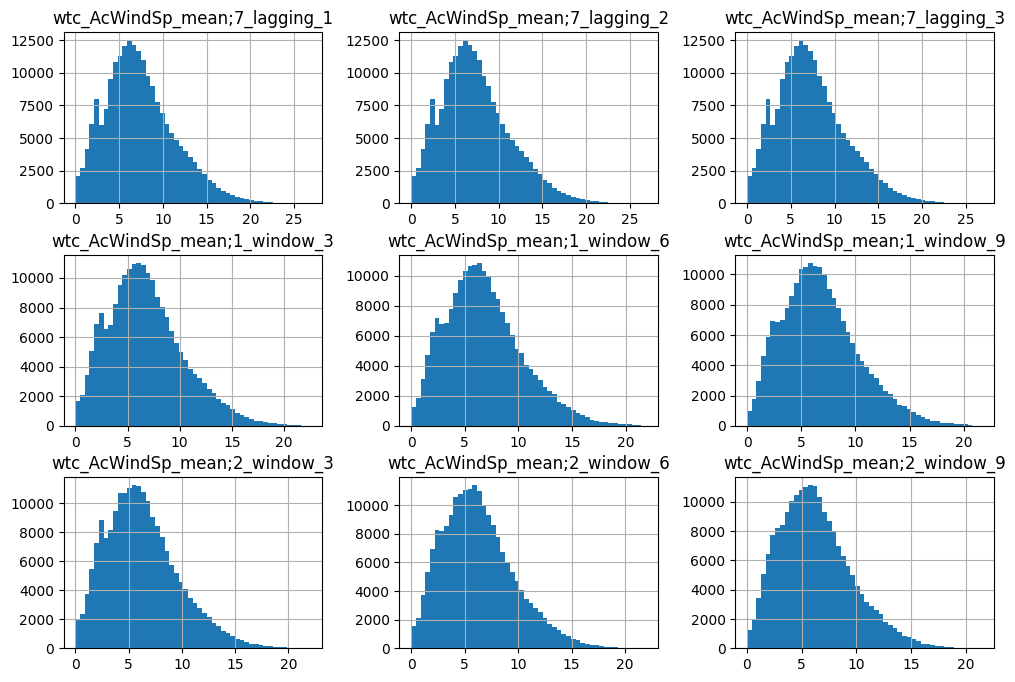

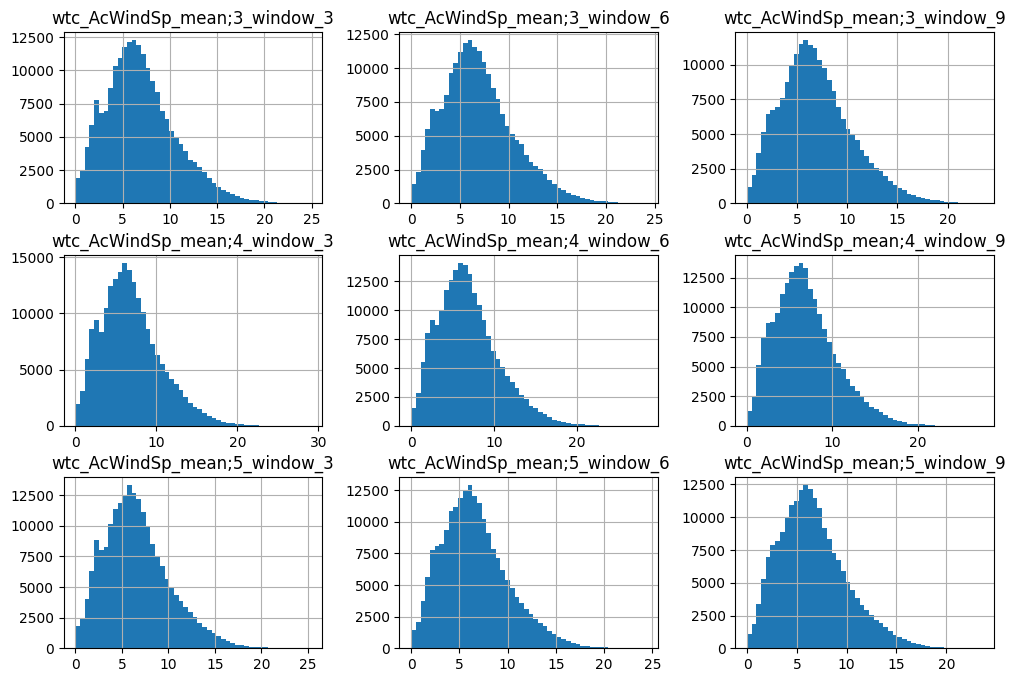

In [14]:
columns = complete_data.columns
iterations = len(columns) // 9
for i in range(iterations):
    complete_data[columns[i*9: (i+1)*9]].hist(bins=50, figsize=(12, 8))
    plt.show()

/Users/joarsolvang/Documents/Github/floris-timeseries/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


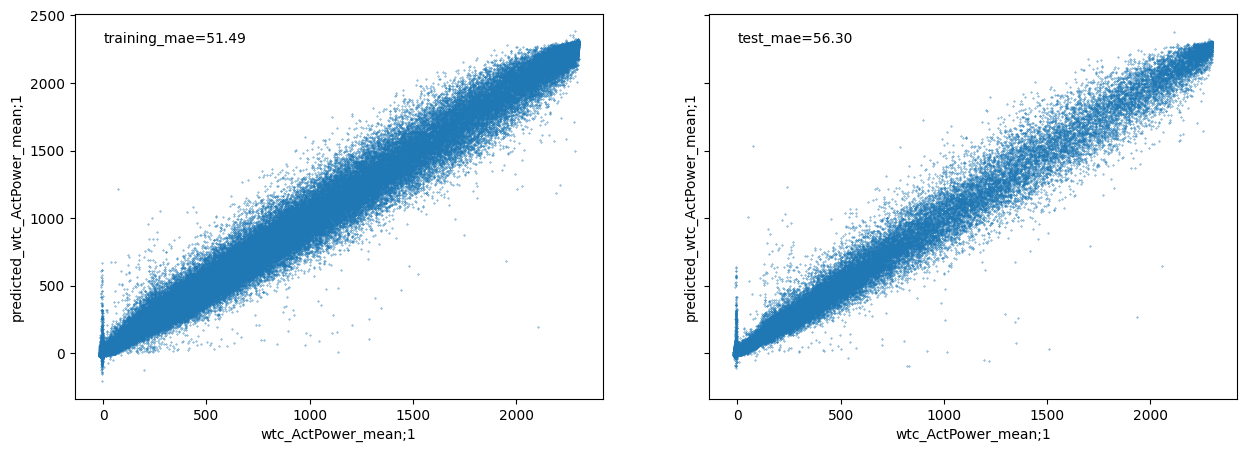

In [15]:
model = HistGradientBoostingRegressor()
model.fit(training_inputs, training_target_set[[target_tag]])
test_predictions = model.predict(testing_inputs)
training_predictions = model.predict(training_inputs)

test_predictions_df = pd.DataFrame(
    test_predictions,
    columns=["predicted_power"],
    index=testing_inputs.index
    )


training_predictions_df = pd.DataFrame(
    training_predictions,
    columns=["predicted_power"],
    index=training_inputs.index
    )

test_mae = mean_absolute_error(testing_target_set[[target_tag]], test_predictions_df)
training_mae = mean_absolute_error(training_target_set[[target_tag]], training_predictions_df)

fig, ax = plt.subplots(ncols=2, figsize=(15, 5), sharex=True, sharey=True)
ax[0].scatter(training_target_set[[target_tag]], training_predictions_df, s=.1)
ax[0].annotate(text=f"{training_mae=:.2f}", xy=(.1,2300))
ax[0].set_xlabel(target_tag)
ax[0].set_ylabel("predicted_" + target_tag)

ax[1].scatter(testing_target_set[[target_tag]], test_predictions_df, s=.1)
ax[1].annotate(text=f"{test_mae=:.2f}", xy=(.1,2300))
ax[1].set_xlabel(target_tag)
ax[1].set_ylabel("predicted_" + target_tag)
plt.show()

In [16]:
# # Permutation importance
# from sklearn.inspection import permutation_importance


# result = permutation_importance(model, training_inputs, training_target_set[[target_tag]], n_repeats=10, random_state=42)
# feature_importance = pd.DataFrame(
#     result.importances_mean,
#     columns=["feature_importance"])
# feature_importance["tag"] = training_inputs.columns
# feature_importance.sort_values(by="feature_importance", ascending=False)

Let's search for some sources of this error by analysing the delta between the prediction and the actual.

In [17]:
analysis_df = pd.concat([testing_target_set, test_predictions_df], axis=1)
analysis_df["error"] = analysis_df["wtc_ActPower_mean;1"] - analysis_df["predicted_power"]
analysis_df["abs_error"] = abs(analysis_df["error"])


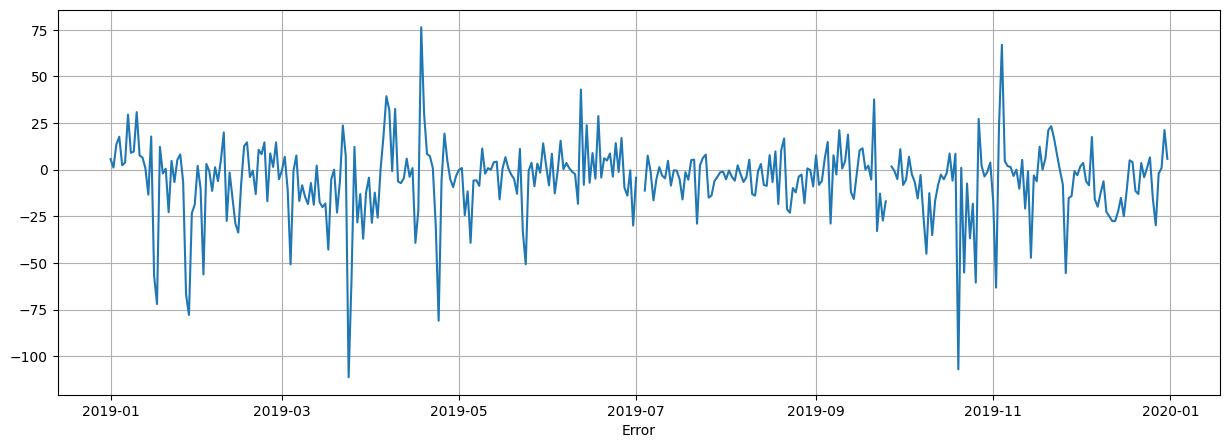

In [18]:
analysis_df_day = analysis_df.resample(pd.Timedelta(days=1)).mean()
analysis_df_hour = analysis_df.resample(pd.Timedelta(hours=1)).mean()


fig, ax = plt.subplots(figsize=(15,5))
ax.plot(analysis_df_day.index, analysis_df_day["error"])
ax.set_xlabel("Time")
ax.set_xlabel("Error")
ax.grid()

There are a couple of spikes in the plot that can be focused on, additionally the model seems to over predict in the winter/spring period. 

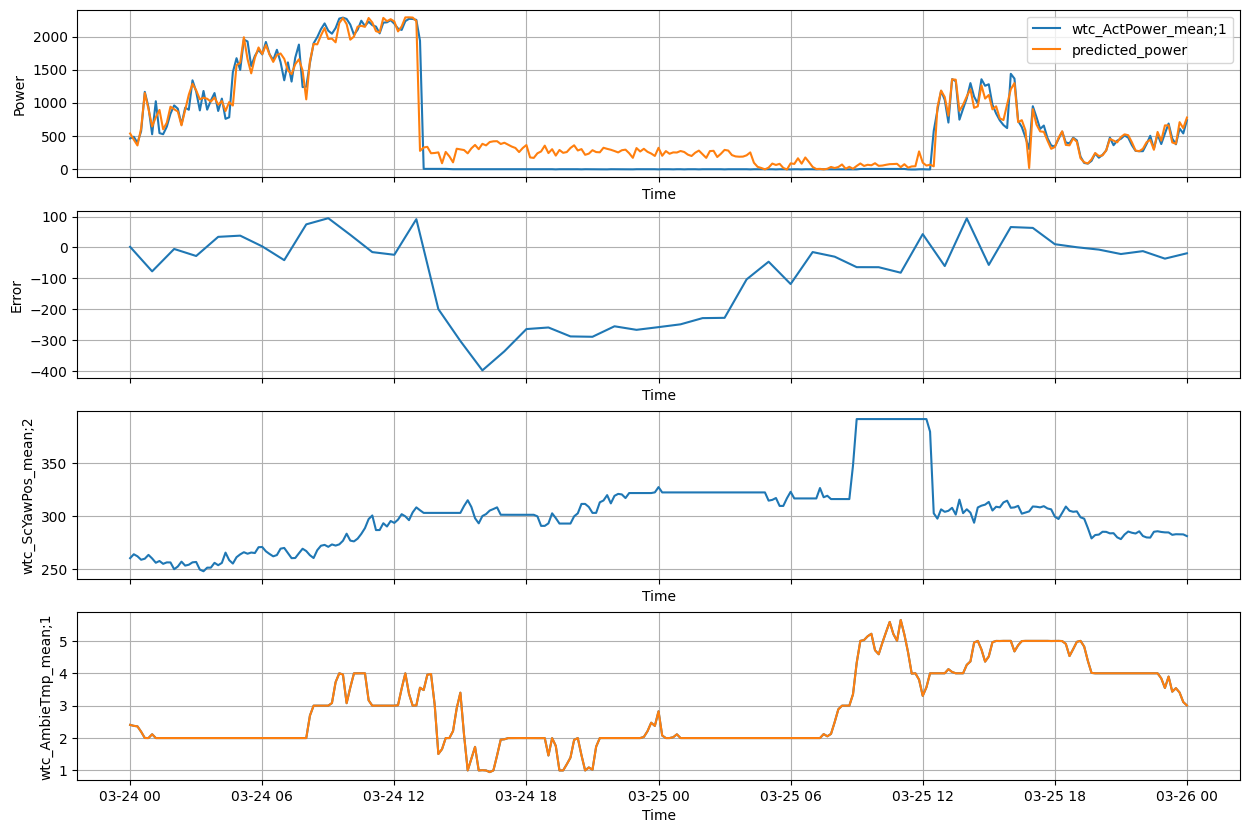

In [19]:
sample_start_time = pd.Timestamp(year=2019, month=3, day=24, tz="UTC")
sample_end_time = sample_start_time + pd.Timedelta(days=2)

fig, ax = plt.subplots(nrows=4, figsize=(15,10), sharex=True)

ax[0].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["wtc_ActPower_mean;1"], label="wtc_ActPower_mean;1")
ax[0].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["predicted_power"], label="predicted_power")
ax[0].legend()
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Power")
ax[0].grid()

ax[1].plot(analysis_df_hour[sample_start_time:sample_end_time].index, analysis_df_hour[sample_start_time:sample_end_time]["error"])
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Error")
ax[1].grid()


ax[2].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["wtc_ScYawPos_mean;1"])
ax[2].set_xlabel("Time")
ax[2].set_ylabel("wtc_ScYawPos_mean;2")
ax[2].grid()

ax[3].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["wtc_AmbieTmp_mean;1"])
ax[3].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["wtc_AmbieTmp_mean;1"])
ax[3].set_xlabel("Time")
ax[3].set_ylabel("wtc_AmbieTmp_mean;1")
ax[3].grid()




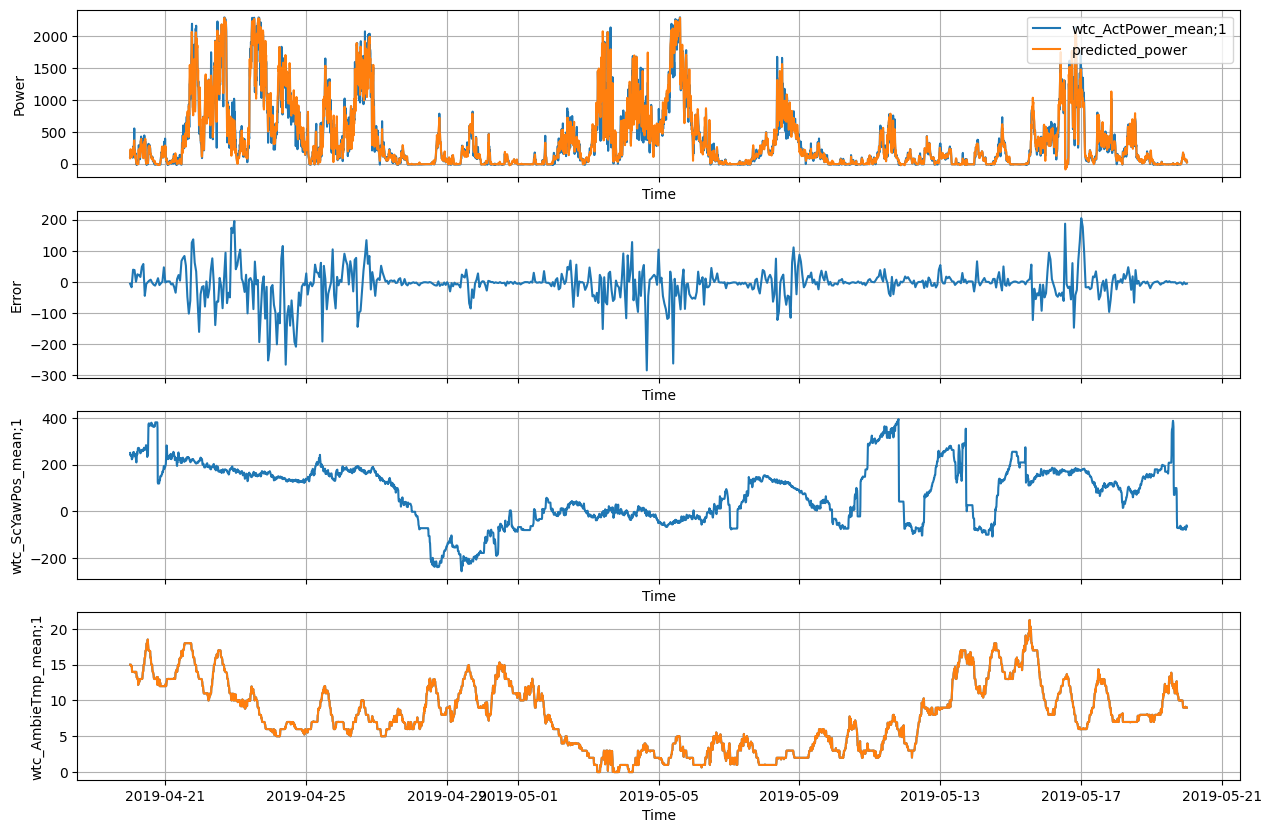

In [20]:
sample_start_time = pd.Timestamp(year=2019, month=4, day=20, tz="UTC")
sample_end_time = sample_start_time + pd.Timedelta(days=30)

fig, ax = plt.subplots(nrows=4, figsize=(15,10), sharex=True)

ax[0].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["wtc_ActPower_mean;1"], label="wtc_ActPower_mean;1")
ax[0].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["predicted_power"], label="predicted_power")
ax[0].legend()
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Power")
ax[0].grid()

ax[1].plot(analysis_df_hour[sample_start_time:sample_end_time].index, analysis_df_hour[sample_start_time:sample_end_time]["error"])
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Error")
ax[1].grid()


ax[2].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["wtc_ScYawPos_mean;1"])
ax[2].set_xlabel("Time")
ax[2].set_ylabel("wtc_ScYawPos_mean;1")
ax[2].grid()

ax[3].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["wtc_AmbieTmp_mean;1"])
ax[3].plot(analysis_df[sample_start_time:sample_end_time].index, analysis_df[sample_start_time:sample_end_time]["wtc_AmbieTmp_mean;1"])
ax[3].set_xlabel("Time")
ax[3].set_ylabel("wtc_AmbieTmp_mean;1")
ax[3].grid()




In [21]:
analysis_df["hour"] = analysis_df.index.hour
analysis_df["month"] = analysis_df.index.month
analysis_df["wtc_NacelPos_mean;1_bin"] = pd.cut(analysis_df["wtc_NacelPos_mean;1"], bins = 36)
analysis_df["wtc_NacelPos_mean;1_bin_mid"] = analysis_df["wtc_NacelPos_mean;1_bin"].apply(lambda x: x.mid)
analysis_df["wtc_NacelPos_mean;1_bin_mid"] = analysis_df["wtc_NacelPos_mean;1_bin_mid"].astype(float)
analysis_df = analysis_df.drop(labels="wtc_NacelPos_mean;1_bin", axis=1)

<Axes: xlabel='hour'>

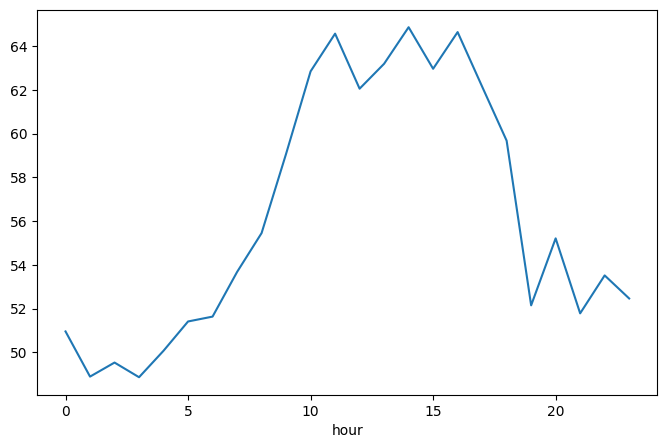

In [22]:
analysis_df.groupby("hour").mean()["abs_error"].plot(figsize=(8,5))

<Axes: xlabel='hour'>

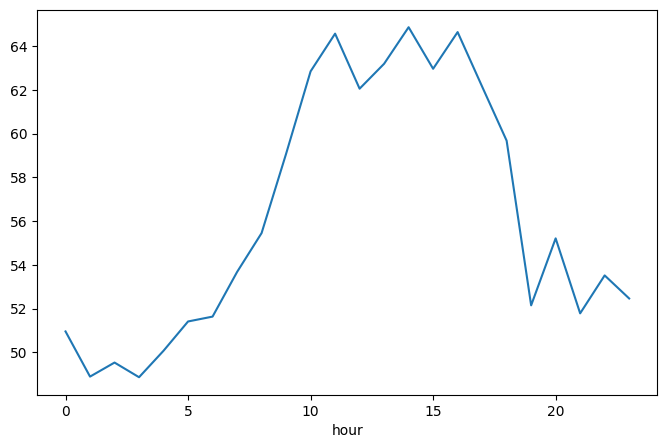

In [23]:
analysis_df.groupby("hour").mean()["abs_error"].plot(figsize=(8,5))

<Axes: xlabel='month'>

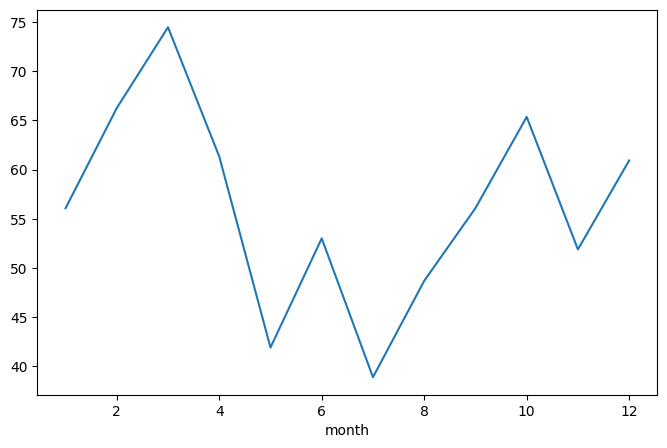

In [24]:
analysis_df.groupby("month").mean()["abs_error"].plot(figsize=(8,5))

In [25]:
import requests

def load_turbine_metadata(*, force_download: bool = False) -> pd.DataFrame:
    file_path = CACHE_DIR / "turbine_metadata.csv"
    if not file_path.exists() or force_download:
        response = requests.get(
            "https://zenodo.org/records/14870023/files/Hill_of_Towie_turbine_metadata.csv?download=1",
            headers={"Accept": "text/csv"},
            timeout=10,
        )
        response.raise_for_status()
        file_path.parent.mkdir(parents=True, exist_ok=True)
        file_path.write_text(response.content.decode("utf-8-sig"), encoding="utf-8")
    return pd.read_csv(file_path)

In [26]:
turbine_data = load_turbine_metadata()

<Axes: xlabel='wtc_NacelPos_mean;1_bin_mid'>

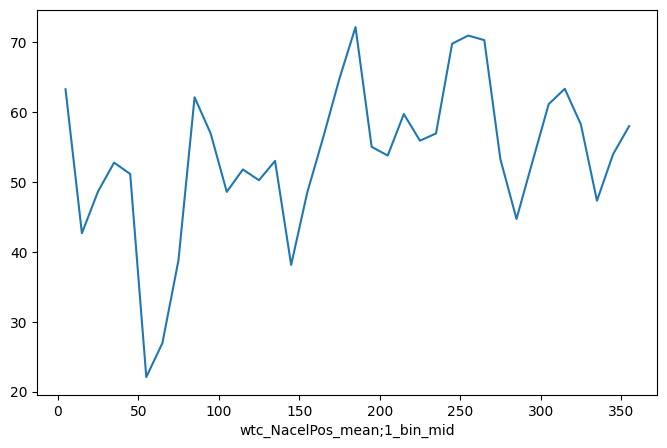

In [27]:
analysis_df.groupby("wtc_NacelPos_mean;1_bin_mid").mean()["abs_error"].plot(figsize=(8,5))